# Initial model comparison ? Step 7

Compare fixed majority/prior baselines, L2 multinomial logistic regression, and a depth-4 decision tree. Fit fresh complete pipelines on 1,600 development-training records and evaluate 400 validation records. No hyperparameter search, final model selection, or test-data evaluation occurs here.

See [the problem definition](../reports/PROJECT_REPORT.md), [preprocessing contract](../reports/PREPROCESSING.md), [comparison report](../reports/MODEL_COMPARISON.md), and [local setup](../LOCAL_SETUP.md).

In [1]:
from pathlib import Path
import importlib.metadata
import sys
import pandas as pd

ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "src/schema.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.config import MODEL_SEED
from src.compare_models import model_candidates, run_comparison
print("Interpreter:", sys.executable)
print("Seed:", MODEL_SEED)
print("Versions:", {name: importlib.metadata.version(name) for name in ["numpy", "pandas", "scikit-learn", "joblib"]})


Interpreter: C:\Users\jettw\Documents\Fall2026\ML\EcoSystem\.venv\Scripts\python.exe
Seed: 42
Versions: {'numpy': '2.4.6', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'joblib': '1.6.0'}


## Fixed candidates before evaluation

The majority dummy always predicts the most common training label. The prior dummy returns the empirical training-class probabilities and the same hard predictions. Logistic regression minimizes L2-regularized multinomial negative log-likelihood using L-BFGS; the tree greedily reduces Gini impurity with maximum depth 4 and at least 5 rows per leaf. All candidates use fresh training-fitted preprocessing. No class weights or calibration are applied.

In [2]:
display(pd.DataFrame([
    {"candidate": name, "estimator": type(estimator).__name__, "settings": estimator.get_params(deep=False)}
    for name, estimator in model_candidates().items()
]))


,candidate,estimator,settings
0,majority,DummyClassifier,"{'constant': None, 'random_state': 42, 'strate..."
1,prior_probability,DummyClassifier,"{'constant': None, 'random_state': 42, 'strate..."
2,logistic_regression,LogisticRegression,"{'C': 1.0, 'class_weight': None, 'dual': False..."
3,shallow_tree,DecisionTreeClassifier,"{'ccp_alpha': 0.0, 'class_weight': None, 'crit..."


## Fit and compare development metrics

Macro F1 remains the primary metric. The workflow records accuracy, balanced accuracy, log loss, per-class precision/recall/F1/support, confusion matrices, fit time, settings, convergence diagnostics, and warnings. Numeric target encoding aligns log loss with the explicit healthy/moderate stress/high stress probability order.

In [3]:
comparison = run_comparison()
table = pd.read_csv(ROOT / "reports/model_comparison.csv")
display(table[["model", "train_accuracy", "validation_accuracy", "train_macro_f1", "validation_macro_f1", "validation_log_loss", "fit_seconds", "fit_warning_count", "accuracy_gap", "macro_f1_gap"]])
print("Status:", comparison["status"])
print("Test table loaded:", comparison["test_table_loaded"])


,model,train_accuracy,validation_accuracy,train_macro_f1,validation_macro_f1,validation_log_loss,fit_seconds,fit_warning_count,accuracy_gap,macro_f1_gap
0,majority,0.464375,0.465,0.211410,0.211604,19.283355,0.061906,0,-0.000625,-0.000194
1,prior_probability,0.464375,0.465,0.211410,0.211604,0.975474,0.015206,0,-0.000625,-0.000194
2,logistic_regression,0.615000,0.600,0.547073,0.532705,0.817674,0.034954,0,0.015000,0.014368
3,shallow_tree,0.663750,0.635,0.469417,0.449581,0.864563,0.018217,0,0.028750,0.019836


Status: initial_fixed_setting_comparison; no tuning or final model selection
Test table loaded: False


## Per-class validation results and convergence

All three classes are included even when a candidate never predicts one of them. Undefined precision/F1 is reported as zero. Inspect the healthy minority class separately; overall accuracy alone cannot show whether it is recovered.

In [4]:
per_class = []
for name, model in comparison["models"].items():
    print(name, "| diagnostics:", model["diagnostics"], "| warnings:", model["fit_warnings"])
    for label, metrics in model["metrics"]["validation"]["per_class"].items():
        per_class.append({"model": name, "class": label, **metrics})
display(pd.DataFrame(per_class))


majority | diagnostics: {'fitted_class_priors_estimator_order': [0.12, 0.415625, 0.464375]} | warnings: []
prior_probability | diagnostics: {'fitted_class_priors_estimator_order': [0.12, 0.415625, 0.464375]} | warnings: []
logistic_regression | diagnostics: {'iterations': [42]} | warnings: []
shallow_tree | diagnostics: {'actual_depth': 4, 'leaves': 16} | warnings: []


,model,class,precision,recall,f1,support
0,majority,healthy,0.000000,0.000000,0.000000,48
1,majority,moderate_stress,0.465000,1.000000,0.634812,186
2,majority,high_stress,0.000000,0.000000,0.000000,166
3,prior_probability,healthy,0.000000,0.000000,0.000000,48
4,prior_probability,moderate_stress,0.465000,1.000000,0.634812,186
5,prior_probability,high_stress,0.000000,0.000000,0.000000,166
6,logistic_regression,healthy,0.571429,0.250000,0.347826,48
7,logistic_regression,moderate_stress,0.573460,0.650538,0.609572,186
8,logistic_regression,high_stress,0.636905,0.644578,0.640719,166
9,shallow_tree,healthy,0.000000,0.000000,0.000000,48


## Validation plots

These figures describe the fixed initial comparison. Validation remains development evidence; the provided test split is still reserved.

### Training and validation metrics

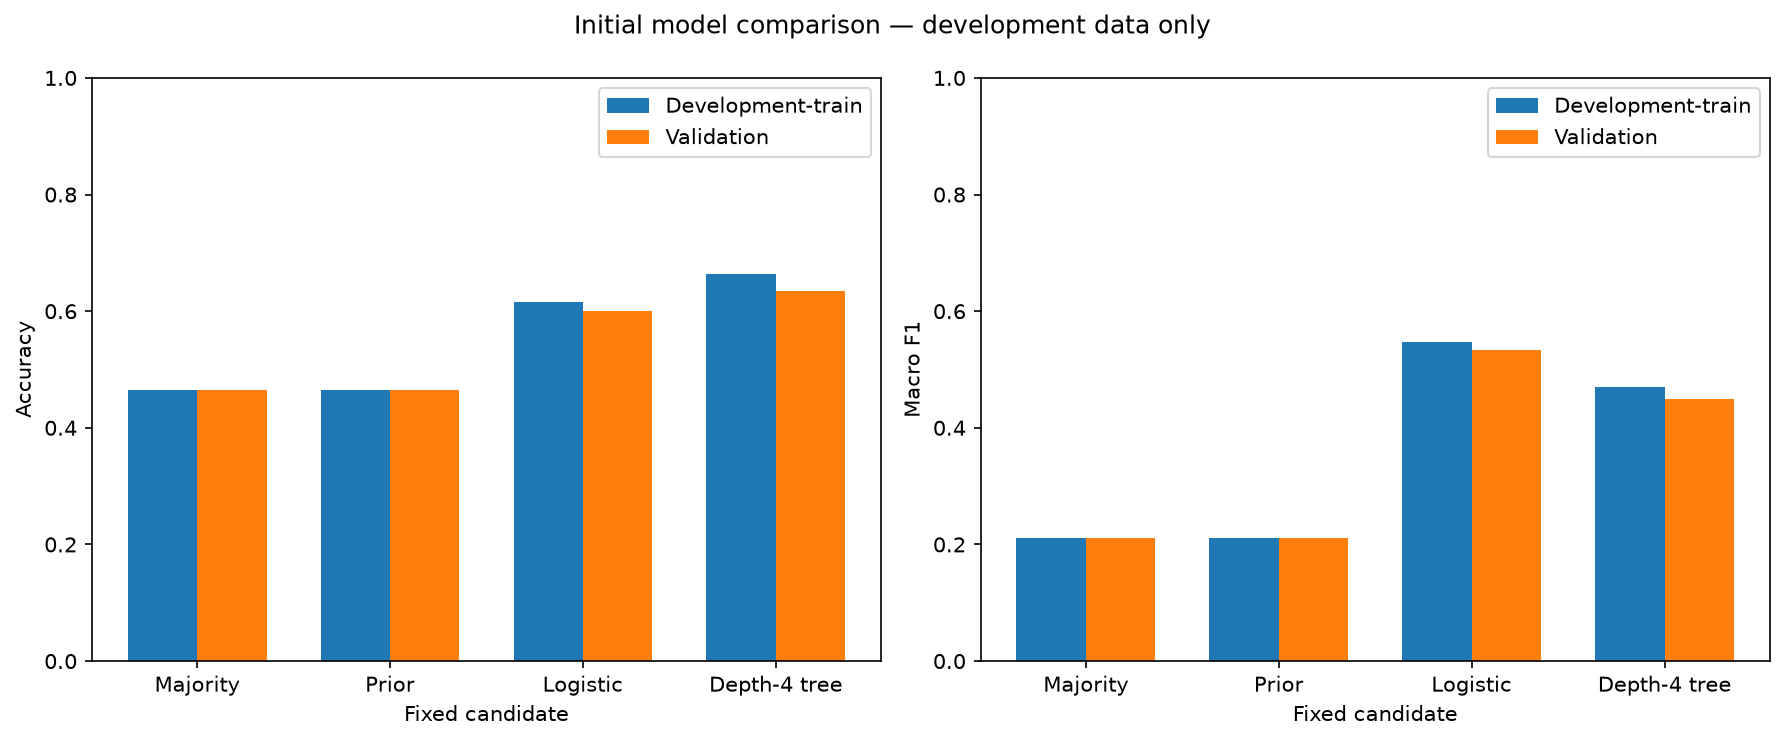

The train/validation gaps are a first check of generalization, not proof of it. Accuracy can hide poor healthy-class recall; compare macro F1 and the per-class results before judging the candidates.

### Validation confusion matrices

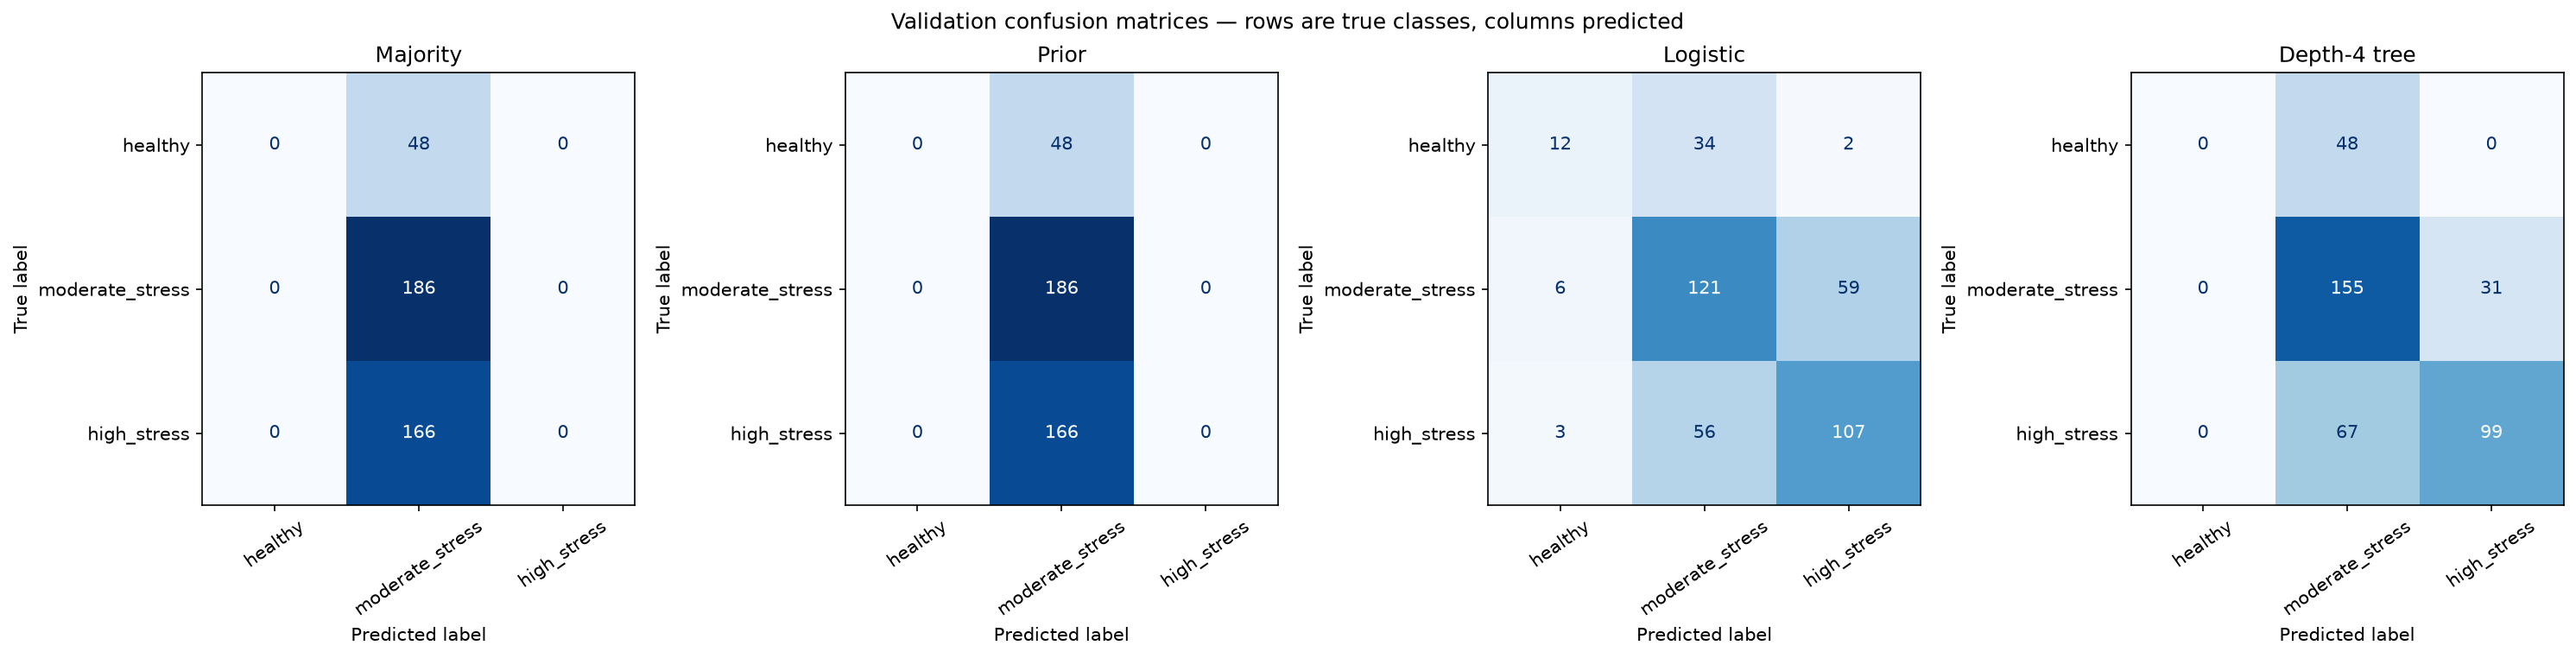

Both dummy baselines predict only the majority class and miss every healthy/high-stress record. The logistic and tree matrices expose which class confusions remain; all panels use the same class order and color scale.

### Per-class recall

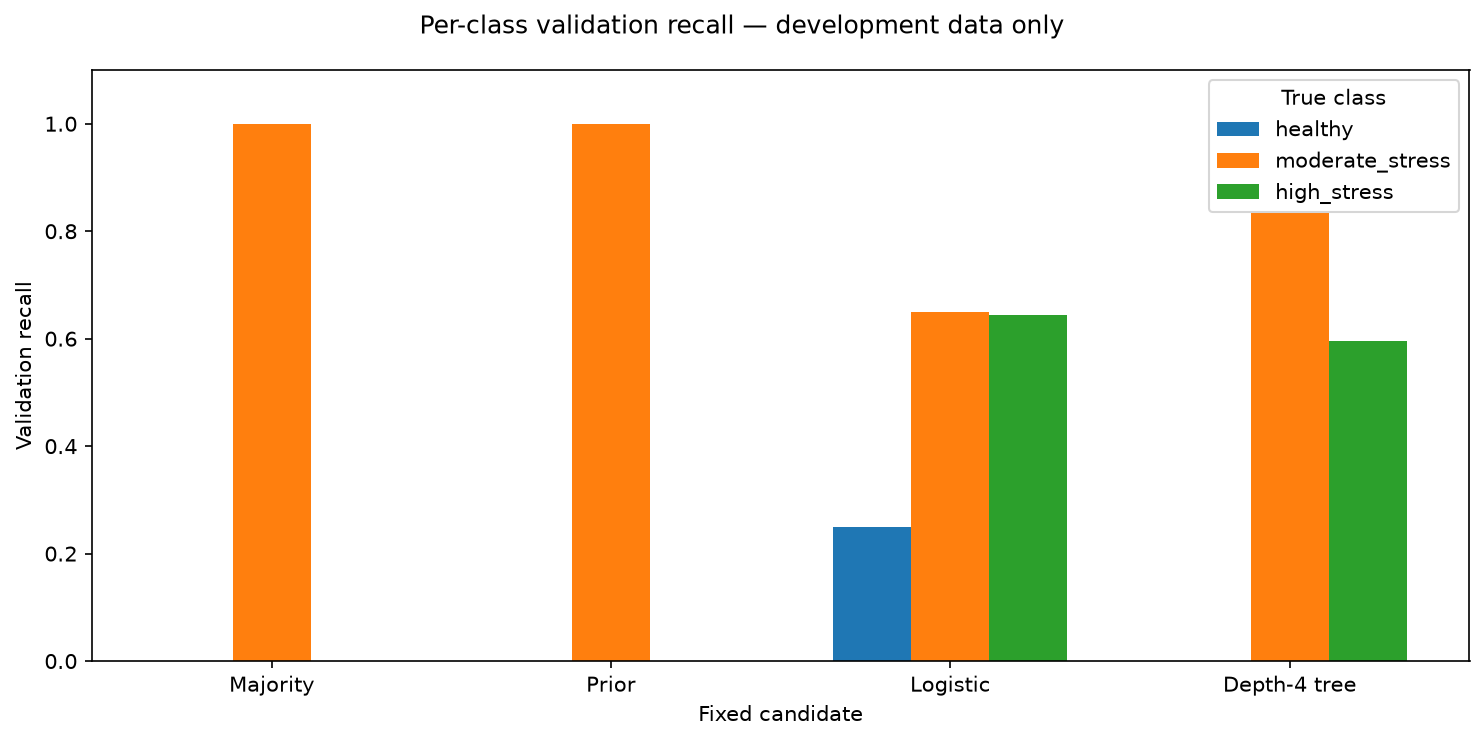

Recall measures the fraction of each true class recovered. The minority healthy class must be assessed separately from aggregate accuracy; these estimates come from one 400-record validation partition and are not final test results.

In [5]:
from IPython.display import Image, Markdown, display
for figure in comparison["figures"]:
    display(Markdown("### " + figure["title"]))
    display(Image(filename=str(ROOT / "reports" / figure["file"])))
    display(Markdown(figure["interpretation"]))


## Interpretation and next steps

The highest initial validation macro F1 belongs to logistic regression, while the shallow tree has higher accuracy. The per-class results explain why a single accuracy ranking is insufficient. Train/validation gaps are modest, so these runs do not show a dramatic memorization gap; restricted model flexibility and class imbalance can still produce underfitting and poor minority recall. This is one development split, not stable model superiority.

The hard-majority log loss is dominated by zero probabilities clipped to float64 machine epsilon. The prior-probability dummy is the useful constant-probability reference. All saved candidate pipelines reproduced validation probabilities after reloading.

The [report](../reports/MODEL_COMPARISON.md) records settings, limitations, metrics, and artifact paths. Synthetic-data performance does not validate real-plant diagnosis. Step 8 connects the classifier to the class math; Step 9 handles declared tuning/selection, and Step 11 performs final test evaluation.